In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [4]:
crosstab["best_seller_proportion"] = (
    crosstab[True] / crosstab.sum(axis=1)
)

crosstab.sort_values(
    "best_seller_proportion",
    ascending=False
).head(10)

isBestSeller,False,True,best_seller_proportion
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000


In [8]:
from scipy.stats import chi2_contingency
import numpy as np


In [9]:
table = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


In [10]:
n = table.to_numpy().sum()
r, k = table.shape

cramers_v = np.sqrt(chi2 / (n * min(r - 1, k - 1)))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


In [ ]:
The Chi-square test shows a statistically significant relationship between product category and best-seller status because the p-value is effectively 0. This means best-seller status is not independent of product category. However, Cramér’s V is about 0.12, which indicates that the association is weak.

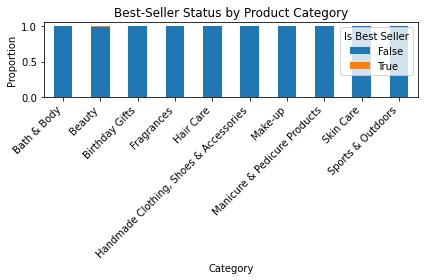

In [11]:
top_10_categories = df["category"].value_counts().head(10).index

plot_data = pd.crosstab(
    df[df["category"].isin(top_10_categories)]["category"],
    df[df["category"].isin(top_10_categories)]["isBestSeller"],
    normalize="index"
)

plot_data.plot(kind="bar", stacked=True)

plt.title("Best-Seller Status by Product Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Is Best Seller")
plt.tight_layout()
plt.show()

In [12]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

print("Original rows:", len(df))
print("Rows after removing outliers:", len(df_no_outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Original rows: 2443651
Rows after removing outliers: 2115963
Lower bound: -44.01
Upper bound: 99.99000000000001


In [13]:
import seaborn as sns

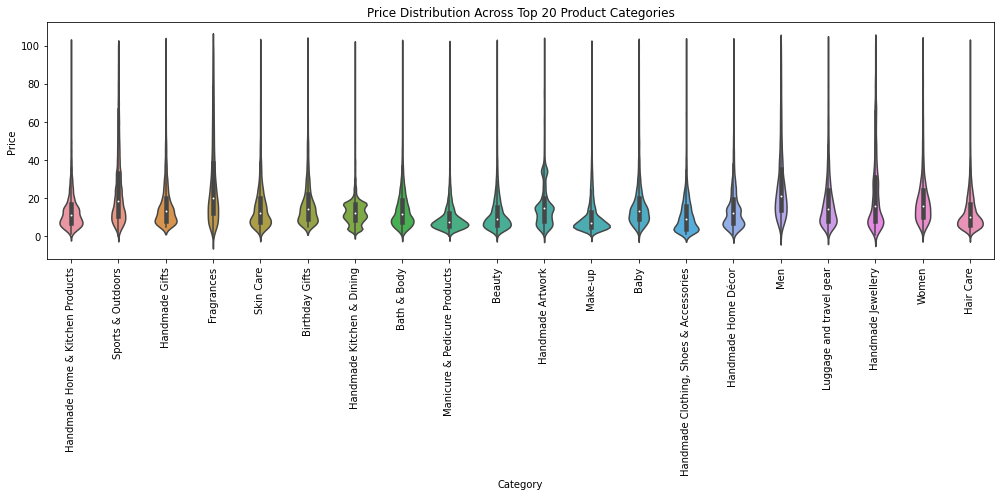

In [14]:
top_20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

top_20_df = df_no_outliers[
    df_no_outliers["category"].isin(top_20_categories)
]

plt.figure(figsize=(14, 7))

sns.violinplot(
    data=top_20_df,
    x="category",
    y="price"
)

plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [15]:
median_prices = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_prices.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [ ]:
the category with the highest median price is Desktop PCs, with a median price of approximately £ 74.00.

In [16]:
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

top_10_df = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories)
]

avg_prices = (
    top_10_df
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_prices

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

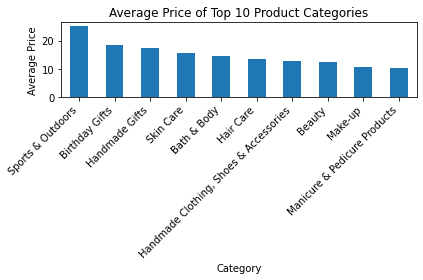

In [17]:
avg_prices.plot(kind="bar")

plt.title("Average Price of Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [18]:
all_avg_prices = (
    df_no_outliers
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

all_avg_prices.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

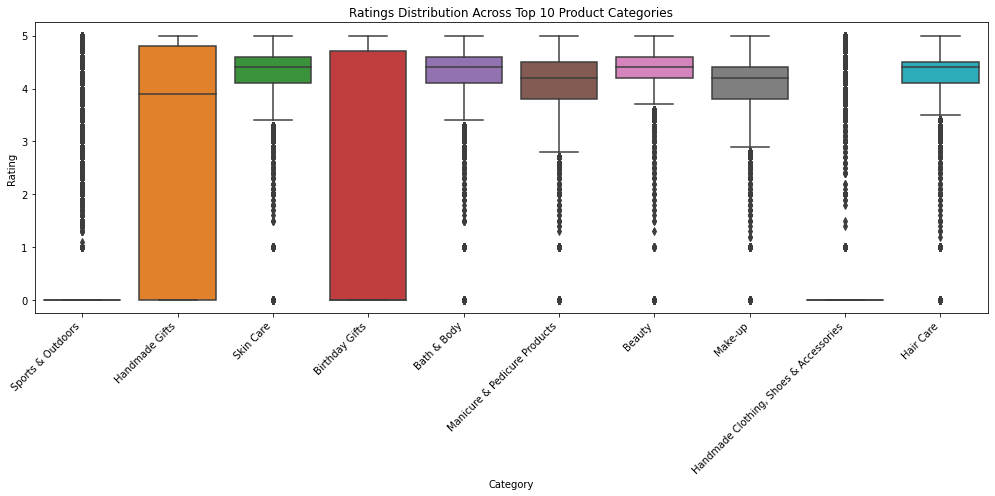

In [19]:
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

ratings_top10 = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories)
]

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=ratings_top10,
    x="category",
    y="stars"
)

plt.title("Ratings Distribution Across Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
median_ratings = (
    df_no_outliers
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_ratings.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

In [ ]:
Computer Memory has the highest median customer rating at 4.7. Several other categories also have strong median ratings around 4.6, suggesting consistently high customer satisfaction in those categories.

In [21]:
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])
print("Correlation between price and stars:", correlation)

Correlation between price and stars: -0.0776729987818095


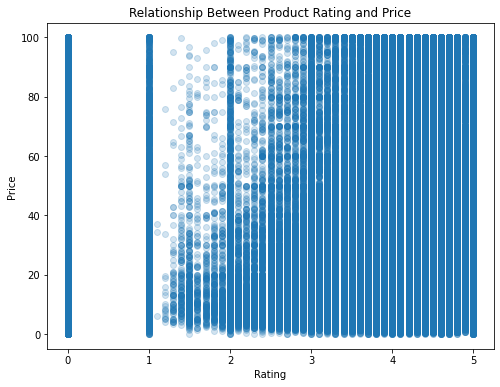

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df_no_outliers["stars"],
    df_no_outliers["price"],
    alpha=0.2
)

plt.title("Relationship Between Product Rating and Price")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()

In [ ]:
The correlation between product price and rating is approximately -0.078, indicating a very weak negative relationship. Product price does not appear to have a meaningful linear relationship with customer ratings.

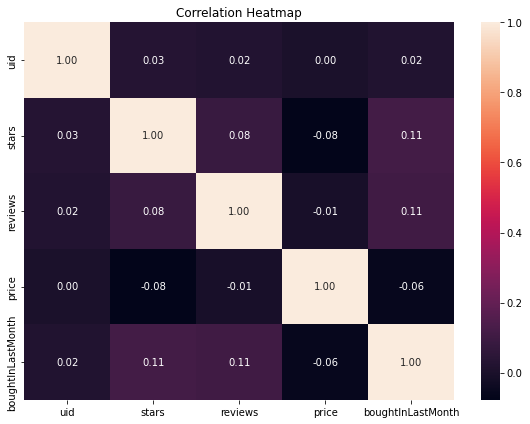

In [23]:
numeric_df = df_no_outliers.select_dtypes(include="number")

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

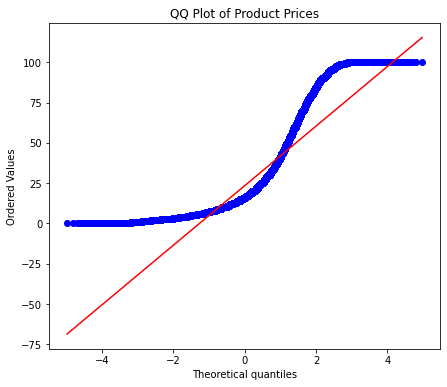

In [24]:
from scipy import stats

plt.figure(figsize=(7, 6))

stats.probplot(
    df_no_outliers["price"],
    dist="norm",
    plot=plt
)

plt.title("QQ Plot of Product Prices")
plt.show()

In [ ]:
Correlation heatmap: Most numerical variables show weak correlations. Product price has almost no linear relationship with product rating, supporting the earlier correlation result.

QQ plot: Product prices do not follow a normal distribution because the observed values deviate substantially from the theoretical normal line.

In [ ]:
Business Summary
Product category is statistically related to best-seller status, although the association is weak. Grocery shows one of the highest best-seller proportions. Product prices vary substantially across categories: Desktop PCs have the highest median price, while Motherboards have the highest average price after outliers are removed. Computer Memory has the highest median customer rating. Price and customer ratings show almost no meaningful correlation, suggesting that more expensive products are not necessarily rated better. The price distribution also remains non-normal, so median-based measures and robust methods are useful when analysing pricing data.